# TA-03: Data-Driven Monte Carlo Simulation
## Forecasting Harga Saham Apple (AAPL)

**Pertanyaan Simulasi:** Berapa probabilitas harga saham AAPL akan turun lebih dari 10% dalam 30 hari ke depan?

**Dataset:** Historical Stock Price Apple (AAPL) dari Kaggle

---

## Langkah 1: Eksplorasi Data Kaggle
### 1.1 Mengunduh dan Membaca Data

In [1]:
# Import library yang dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Membaca dataset saham AAPL dari Kaggle
FILE_INPUT = Path("AAPL_stock_data.csv")

if not FILE_INPUT.exists():
    raise FileNotFoundError(
        f"File {FILE_INPUT} tidak ditemukan. "
        "Pastikan CSV berada di folder proyek."
    )

df = pd.read_csv(FILE_INPUT)

# Menampilkan informasi awal dataset
print("=" * 60)
print("INFORMASI DATASET SAHAM APPLE (AAPL)")
print("=" * 60)
print(f"Jumlah baris  : {len(df)}")
print(f"Jumlah kolom  : {len(df.columns)}")
print(f"\nNama kolom: {df.columns.tolist()}")
print("\nLima baris pertama:")
df.head()

INFORMASI DATASET SAHAM APPLE (AAPL)
Jumlah baris  : 10971
Jumlah kolom  : 8

Nama kolom: ['Unnamed: 0', 'open', 'high', 'low', 'close', 'adjclose', 'volume', 'ticker']

Lima baris pertama:


,Unnamed: 0,open,high,low,close,adjclose,volume,ticker
0,1980-12-12,0.128348,0.128906,0.128348,0.128348,0.099192,469033600,AAPL
1,1980-12-15,0.122210,0.122210,0.121652,0.121652,0.094017,175884800,AAPL
2,1980-12-16,0.113281,0.113281,0.112723,0.112723,0.087117,105728000,AAPL
3,1980-12-17,0.115513,0.116071,0.115513,0.115513,0.089273,86441600,AAPL
4,1980-12-18,0.118862,0.119420,0.118862,0.118862,0.091861,73449600,AAPL


### 1.2 Data Cleaning (Pembersihan Data)

In [2]:
# Merapikan nama kolom tanggal
df = df.rename(columns={"Unnamed: 0": "tanggal"})

# Memastikan tipe data benar
df["tanggal"] = pd.to_datetime(df["tanggal"], errors="coerce")
df["adjclose"] = pd.to_numeric(df["adjclose"], errors="coerce")

jumlah_awal = len(df)
print(f"Jumlah data awal: {jumlah_awal}")

# Menghapus baris dengan nilai null
print(f"\nJumlah nilai kosong per kolom:")
print(df.isnull().sum())

# Membersihkan data:
# - Hapus baris null pada kolom kunci
# - Filter hanya ticker AAPL
# - Hapus harga negatif atau nol
df = df.dropna(subset=["tanggal", "adjclose", "ticker"])
df = df[df["ticker"].astype(str).str.upper() == "AAPL"]
df = df[df["adjclose"] > 0]

# Mengambil periode 2015 sampai 20 Juni 2024 (data yang relevan)
df = df[
    (df["tanggal"] >= "2015-01-01")
    & (df["tanggal"] <= "2024-06-20")
].copy()

# Urutkan berdasarkan tanggal dan hapus duplikat
df = df.sort_values("tanggal")
jumlah_sebelum = len(df)
df = df.drop_duplicates(subset="tanggal", keep="last").reset_index(drop=True)
jumlah_duplikat = jumlah_sebelum - len(df)

print(f"\nHasil pembersihan:")
print(f"Data awal             : {jumlah_awal} baris")
print(f"Tanggal duplikat      : {jumlah_duplikat} baris dihapus")
print(f"Data setelah cleaning : {len(df)} baris")
print(f"Periode data          : {df['tanggal'].min().date()} s/d {df['tanggal'].max().date()}")

Jumlah data awal: 10971

Jumlah nilai kosong per kolom:
tanggal     0
open        0
high        0
low         0
close       0
adjclose    0
volume      0
ticker      0
dtype: int64

Hasil pembersihan:
Data awal             : 10971 baris
Tanggal duplikat      : 0 baris dihapus
Data setelah cleaning : 2382 baris
Periode data          : 2015-01-02 s/d 2024-06-20


### 1.3 Parameter Extraction — Menghitung Return Harian, Mean (μ), dan Standar Deviasi (σ)

Variabel acak yang digunakan: **Daily Return** (return harian).

$$\text{Return}_t = \frac{P_t - P_{t-1}}{P_{t-1}}$$

In [3]:
# Menghitung return harian berdasarkan harga adjusted close
df["return_harian"] = df["adjclose"].pct_change()

# Menghapus baris pertama (NaN karena tidak ada harga sebelumnya)
returns = df["return_harian"].dropna()

# === PARAMETER EXTRACTION (PENTING) ===
# Menghitung Mean (μ) dan Standar Deviasi (σ) dari return harian
rata_return = returns.mean()      # μ (mu)
std_return = returns.std(ddof=1)   # σ (sigma)

print("=" * 60)
print("PARAMETER EXTRACTION - STATISTIK DESKRIPTIF")
print("=" * 60)
print(f"Jumlah data return valid : {len(returns)}")
print(f"")
print(f">>> Mean (μ) return harian       : {rata_return:.8f}")
print(f">>> Standar Deviasi (σ) return    : {std_return:.8f}")
print(f"")
print(f"Return minimum           : {returns.min():.8f}")
print(f"Return maksimum          : {returns.max():.8f}")
print(f"Median return            : {returns.median():.8f}")
print(f"")
print("Statistik deskriptif lengkap:")
print(returns.describe())

PARAMETER EXTRACTION - STATISTIK DESKRIPTIF
Jumlah data return valid : 2381

>>> Mean (μ) return harian       : 0.00106818
>>> Standar Deviasi (σ) return    : 0.01817138

Return minimum           : -0.12864715
Return maksimum          : 0.11980831
Median return            : 0.00085489

Statistik deskriptif lengkap:
count    2381.000000
mean        0.001068
std         0.018171
min        -0.128647
25%        -0.007516
50%         0.000855
75%         0.010139
max         0.119808
Name: return_harian, dtype: float64


### 1.4 Visualisasi — Histogram Distribusi Return Harian

Histogram ini menunjukkan bahwa distribusi return harian mendekati **distribusi Normal**, sehingga kita akan menggunakan `np.random.normal(μ, σ)` pada simulasi Monte Carlo.

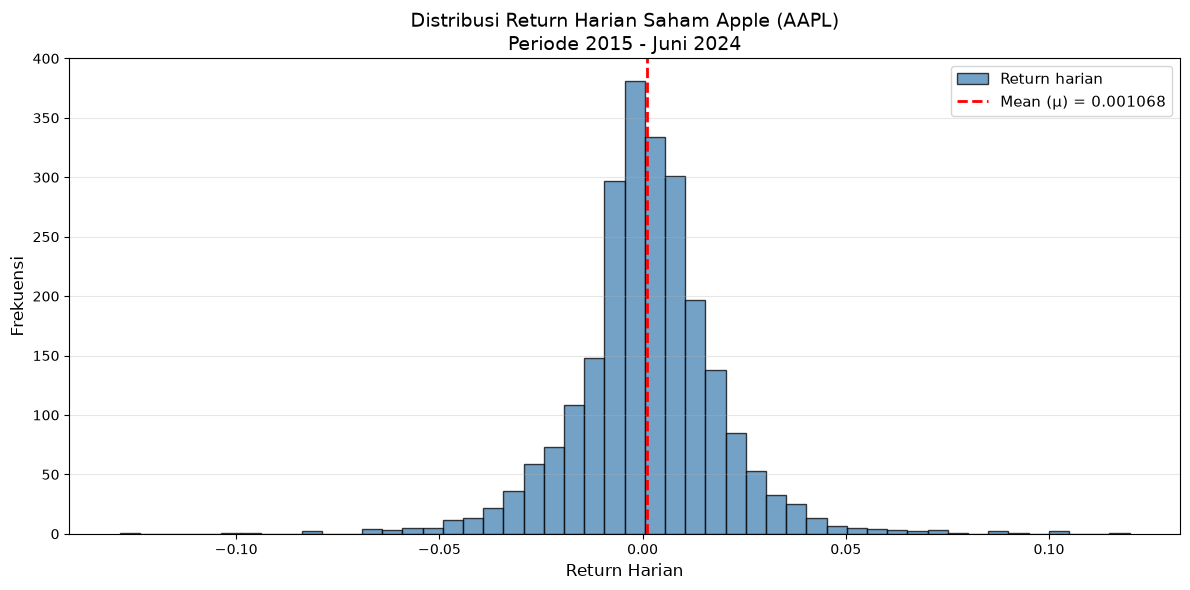


Kesimpulan: Distribusi return harian mendekati distribusi NORMAL.
Parameter yang akan digunakan untuk simulasi:
  μ (Mean)   = 0.00106818
  σ (Std Dev) = 0.01817138


In [4]:
# Visualisasi: Histogram distribusi return harian
plt.figure(figsize=(12, 6))

plt.hist(
    returns,
    bins=50,
    edgecolor="black",
    alpha=0.75,
    color="steelblue",
    label="Return harian"
)

# Menambahkan garis mean
plt.axvline(
    rata_return,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean (μ) = {rata_return:.6f}"
)

plt.title("Distribusi Return Harian Saham Apple (AAPL)\nPeriode 2015 - Juni 2024", fontsize=14)
plt.xlabel("Return Harian", fontsize=12)
plt.ylabel("Frekuensi", fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("histogram_return_notebook.png", dpi=300)
plt.show()

print(f"\nKesimpulan: Distribusi return harian mendekati distribusi NORMAL.")
print(f"Parameter yang akan digunakan untuk simulasi:")
print(f"  μ (Mean)   = {rata_return:.8f}")
print(f"  σ (Std Dev) = {std_return:.8f}")

---
## Langkah 2: Membangun Simulasi Monte Carlo

### Ketentuan Simulasi:
- **Jumlah skenario:** 5.000 iterasi/jalur
- **Horizon:** 30 hari perdagangan ke depan
- **Pembangkitan angka acak:** `np.random.normal(μ, σ)` berdasarkan parameter dari Langkah 1
- **Rumus:** $P_t = P_{t-1} \times (1 + r_{\text{acak}})$ dimana $r_{\text{acak}} \sim N(\mu, \sigma)$

In [5]:
# === KONFIGURASI SIMULASI ===
harga_awal = float(df["adjclose"].iloc[-1])  # Harga terakhir sebagai titik awal
jumlah_simulasi = 5000   # Minimal 5.000 iterasi (sesuai ketentuan)
jumlah_hari = 30         # Simulasi 30 hari ke depan
seed = 42                # Seed untuk reprodusibilitas

print("=" * 60)
print("KONFIGURASI SIMULASI MONTE CARLO")
print("=" * 60)
print(f"Harga awal (terakhir)  : ${harga_awal:.2f}")
print(f"Jumlah simulasi        : {jumlah_simulasi:,} skenario")
print(f"Horizon simulasi       : {jumlah_hari} hari perdagangan")
print(f"Mean return (μ)        : {rata_return:.8f}")
print(f"Std Dev return (σ)     : {std_return:.8f}")
print(f"Random seed            : {seed}")

KONFIGURASI SIMULASI MONTE CARLO
Harga awal (terakhir)  : $209.65
Jumlah simulasi        : 5,000 skenario
Horizon simulasi       : 30 hari perdagangan
Mean return (μ)        : 0.00106818
Std Dev return (σ)     : 0.01817138
Random seed            : 42


In [6]:
# === MENJALANKAN SIMULASI MONTE CARLO ===
np.random.seed(seed)

# Membangkitkan return acak menggunakan distribusi Normal
# dengan parameter μ dan σ yang didapat dari data historis
return_simulasi = np.random.normal(
    loc=rata_return,      # Mean dari data historis
    scale=std_return,     # Std Dev dari data historis
    size=(jumlah_hari, jumlah_simulasi)
)

# Menghitung harga secara kumulatif:
# price_t = price_{t-1} * (1 + return_acak)
faktor_harga = 1 + return_simulasi
faktor_harga = np.maximum(faktor_harga, 0.000001)  # Mencegah harga negatif

harga_simulasi = harga_awal * np.cumprod(faktor_harga, axis=0)

# Menambahkan harga awal sebagai hari ke-0
harga_lengkap = np.vstack([
    np.full(jumlah_simulasi, harga_awal),
    harga_simulasi
])

# Harga akhir di hari ke-30
hasil_akhir = harga_simulasi[-1, :]

print(f"Simulasi selesai!")
print(f"Dimensi matriks harga: {harga_lengkap.shape} (hari x skenario)")
print(f"Contoh 5 harga akhir pertama: {hasil_akhir[:5].round(2)}")

Simulasi selesai!
Dimensi matriks harga: (31, 5000) (hari x skenario)
Contoh 5 harga akhir pertama: [232.31 210.68 210.97 219.51 208.99]


### 2.1 Visualisasi Jalur Simulasi Monte Carlo

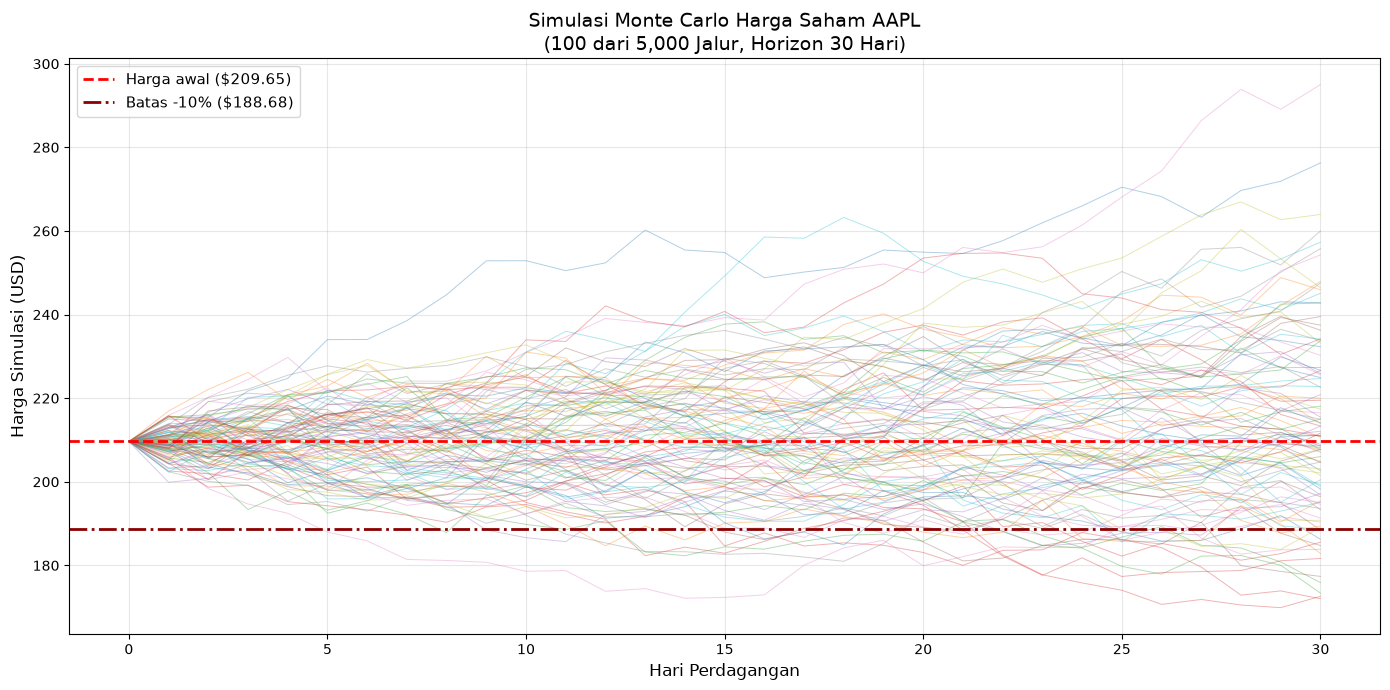

In [7]:
# Grafik jalur simulasi Monte Carlo (menampilkan 100 dari 5.000 jalur)
hari = np.arange(jumlah_hari + 1)

plt.figure(figsize=(14, 7))

# Menampilkan 100 jalur agar grafik mudah dibaca
plt.plot(
    hari,
    harga_lengkap[:, :100],
    linewidth=0.7,
    alpha=0.35
)

# Garis harga awal
plt.axhline(
    harga_awal,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Harga awal (${harga_awal:.2f})"
)

# Garis batas penurunan 10%
batas_10 = harga_awal * 0.90
plt.axhline(
    batas_10,
    color="darkred",
    linestyle="-.",
    linewidth=2,
    label=f"Batas -10% (${batas_10:.2f})"
)

plt.title(
    f"Simulasi Monte Carlo Harga Saham AAPL\n"
    f"(100 dari {jumlah_simulasi:,} Jalur, Horizon {jumlah_hari} Hari)",
    fontsize=14
)
plt.xlabel("Hari Perdagangan", fontsize=12)
plt.ylabel("Harga Simulasi (USD)", fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("jalur_monte_carlo_notebook.png", dpi=300)
plt.show()

### 2.2 Statistik Hasil Simulasi

In [8]:
# Menghitung statistik hasil simulasi
harga_rata = np.mean(hasil_akhir)
harga_median = np.median(hasil_akhir)
harga_min = np.min(hasil_akhir)
harga_max = np.max(hasil_akhir)
persentil_5 = np.percentile(hasil_akhir, 5)
persentil_95 = np.percentile(hasil_akhir, 95)
probabilitas_naik = np.mean(hasil_akhir > harga_awal) * 100

print("=" * 60)
print("STATISTIK HASIL SIMULASI MONTE CARLO")
print("=" * 60)
print(f"Harga awal              : ${harga_awal:.2f}")
print(f"Harga akhir rata-rata   : ${harga_rata:.2f}")
print(f"Harga akhir median      : ${harga_median:.2f}")
print(f"Harga akhir minimum     : ${harga_min:.2f}")
print(f"Harga akhir maksimum    : ${harga_max:.2f}")
print(f"Persentil 5%            : ${persentil_5:.2f}")
print(f"Persentil 95%           : ${persentil_95:.2f}")
print(f"Probabilitas harga naik : {probabilitas_naik:.2f}%")

STATISTIK HASIL SIMULASI MONTE CARLO
Harga awal              : $209.65
Harga akhir rata-rata   : $216.68
Harga akhir median      : $215.72
Harga akhir minimum     : $147.94
Harga akhir maksimum    : $316.20
Persentil 5%            : $183.08
Persentil 95%           : $253.68
Probabilitas harga naik : 61.32%


---
## Langkah 3: Analisis Risiko & Kesimpulan

### Pertanyaan Bisnis:
> **Berapa probabilitas harga saham AAPL akan turun lebih dari 10% dalam 30 hari ke depan?**

### Rumus Probabilitas:
$$P(\text{turun} > 10\%) = \frac{\text{Jumlah skenario dimana harga akhir} < 0.9 \times \text{harga awal}}{\text{Total skenario}}$$

In [9]:
# === ANALISIS RISIKO ===
# Batas penurunan 10% dari harga awal
batas_risiko = harga_awal * 0.90

# Menghitung jumlah skenario dimana harga turun lebih dari 10%
jumlah_rugi_ekstrem = int((hasil_akhir < batas_risiko).sum())

# Menghitung probabilitas
probabilitas_rugi = jumlah_rugi_ekstrem / len(hasil_akhir) * 100

print("=" * 60)
print("ANALISIS RISIKO - PROBABILITAS PENURUNAN > 10%")
print("=" * 60)
print(f"Harga awal                     : ${harga_awal:.2f}")
print(f"Batas penurunan 10%            : ${batas_risiko:.2f}")
print(f"Jumlah total simulasi          : {len(hasil_akhir):,}")
print(f"Skenario turun > 10%           : {jumlah_rugi_ekstrem:,}")
print(f"")
print(f">>> PROBABILITAS TURUN > 10%    : {probabilitas_rugi:.2f}% <<<")
print(f"")
print(f"Interpretasi:")
print(f"Dari {len(hasil_akhir):,} skenario simulasi Monte Carlo,")
print(f"terdapat {jumlah_rugi_ekstrem:,} skenario ({probabilitas_rugi:.2f}%) dimana")
print(f"harga saham AAPL turun lebih dari 10% dalam 30 hari perdagangan.")

ANALISIS RISIKO - PROBABILITAS PENURUNAN > 10%
Harga awal                     : $209.65
Batas penurunan 10%            : $188.68
Jumlah total simulasi          : 5,000
Skenario turun > 10%           : 449

>>> PROBABILITAS TURUN > 10%    : 8.98% <<<

Interpretasi:
Dari 5,000 skenario simulasi Monte Carlo,
terdapat 449 skenario (8.98%) dimana
harga saham AAPL turun lebih dari 10% dalam 30 hari perdagangan.


### 3.1 Visualisasi Hasil — Histogram dengan Garis Batas Risiko

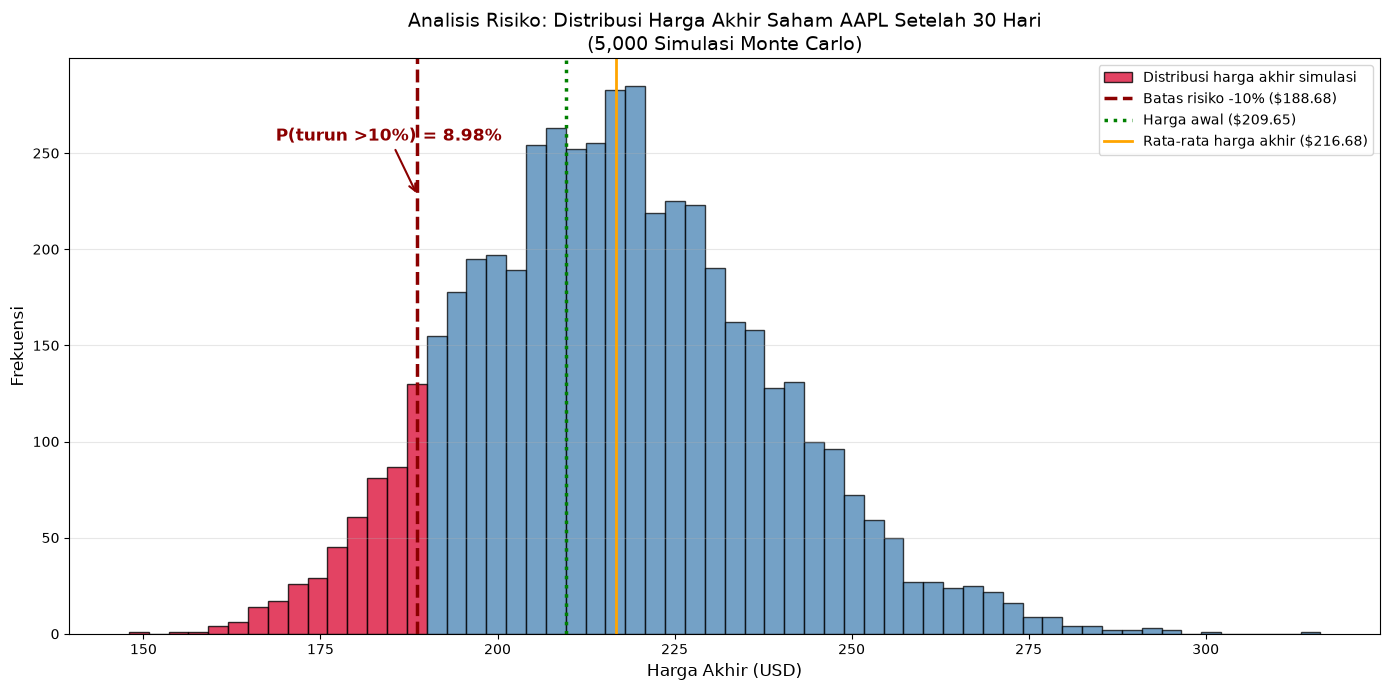

In [10]:
# Histogram distribusi harga akhir dengan garis batas risiko
plt.figure(figsize=(14, 7))

# Histogram harga akhir
n, bins, patches = plt.hist(
    hasil_akhir,
    bins=60,
    edgecolor="black",
    alpha=0.75,
    color="steelblue",
    label="Distribusi harga akhir simulasi"
)

# Mewarnai area risiko (bar di bawah batas 10%)
for patch, left_edge in zip(patches, bins[:-1]):
    if left_edge < batas_risiko:
        patch.set_facecolor("crimson")
        patch.set_alpha(0.8)

# Garis batas risiko 10%
plt.axvline(
    batas_risiko,
    color="darkred",
    linestyle="--",
    linewidth=2.5,
    label=f"Batas risiko -10% (${batas_risiko:.2f})"
)

# Garis harga awal
plt.axvline(
    harga_awal,
    color="green",
    linestyle=":",
    linewidth=2.5,
    label=f"Harga awal (${harga_awal:.2f})"
)

# Garis rata-rata harga akhir
plt.axvline(
    harga_rata,
    color="orange",
    linestyle="-",
    linewidth=2,
    label=f"Rata-rata harga akhir (${harga_rata:.2f})"
)

# Anotasi probabilitas
plt.annotate(
    f"P(turun >10%) = {probabilitas_rugi:.2f}%",
    xy=(batas_risiko, max(n) * 0.8),
    xytext=(batas_risiko - 20, max(n) * 0.9),
    fontsize=12,
    fontweight="bold",
    color="darkred",
    arrowprops=dict(arrowstyle="->", color="darkred", lw=1.5)
)

plt.title(
    f"Analisis Risiko: Distribusi Harga Akhir Saham AAPL Setelah 30 Hari\n"
    f"({jumlah_simulasi:,} Simulasi Monte Carlo)",
    fontsize=14
)
plt.xlabel("Harga Akhir (USD)", fontsize=12)
plt.ylabel("Frekuensi", fontsize=12)
plt.legend(fontsize=10, loc="upper right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("analisis_risiko_notebook.png", dpi=300)
plt.show()

### 3.2 Ringkasan dan Kesimpulan

In [11]:
# === RINGKASAN AKHIR ===
print("=" * 60)
print("RINGKASAN SIMULASI MONTE CARLO SAHAM AAPL")
print("=" * 60)
print("")
print("A. DATA HISTORIS:")
print(f"   Dataset          : Apple (AAPL) Stock Price dari Kaggle")
print(f"   Periode          : 2015-01-02 s/d 2024-06-20")
print(f"   Jumlah data      : {len(returns):,} return harian")
print(f"   Mean (μ)         : {rata_return:.8f}")
print(f"   Std Dev (σ)      : {std_return:.8f}")
print(f"   Distribusi       : Normal")
print("")
print("B. KONFIGURASI SIMULASI:")
print(f"   Jumlah skenario  : {jumlah_simulasi:,} iterasi")
print(f"   Horizon          : {jumlah_hari} hari perdagangan")
print(f"   Generator        : np.random.normal(μ={rata_return:.6f}, σ={std_return:.6f})")
print(f"   Rumus harga      : P_t = P_{{t-1}} × (1 + return_acak)")
print("")
print("C. HASIL SIMULASI:")
print(f"   Harga awal       : ${harga_awal:.2f}")
print(f"   Harga rata-rata  : ${harga_rata:.2f}")
print(f"   Harga median     : ${harga_median:.2f}")
print(f"   Range harga      : ${harga_min:.2f} - ${harga_max:.2f}")
print(f"   VaR 5%           : ${persentil_5:.2f}")
print(f"   P(harga naik)    : {probabilitas_naik:.2f}%")
print("")
print("D. ANALISIS RISIKO:")
print(f"   Pertanyaan       : Berapa probabilitas harga saham AAPL")
print(f"                      turun lebih dari 10% dalam 30 hari?")
print(f"   Batas risiko     : ${batas_risiko:.2f} (= ${harga_awal:.2f} × 0.90)")
print(f"   Skenario risiko  : {jumlah_rugi_ekstrem:,} dari {jumlah_simulasi:,}")
print(f"")
print(f"   ╔══════════════════════════════════════════════════╗")
print(f"   ║  JAWABAN: Probabilitas turun >10% = {probabilitas_rugi:.2f}%     ║")
print(f"   ╚══════════════════════════════════════════════════╝")
print("")
print("E. KESIMPULAN:")
if probabilitas_rugi < 10:
    print(f"   Berdasarkan {jumlah_simulasi:,} simulasi Monte Carlo, probabilitas")
    print(f"   harga saham AAPL turun lebih dari 10% dalam 30 hari perdagangan")
    print(f"   adalah {probabilitas_rugi:.2f}%. Risiko ini tergolong RENDAH (<10%),")
    print(f"   menunjukkan bahwa saham AAPL relatif stabil dalam jangka pendek.")
elif probabilitas_rugi < 25:
    print(f"   Berdasarkan {jumlah_simulasi:,} simulasi Monte Carlo, probabilitas")
    print(f"   harga saham AAPL turun lebih dari 10% dalam 30 hari perdagangan")
    print(f"   adalah {probabilitas_rugi:.2f}%. Risiko ini tergolong SEDANG,")
    print(f"   investor perlu berhati-hati dalam mengambil keputusan.")
else:
    print(f"   Berdasarkan {jumlah_simulasi:,} simulasi Monte Carlo, probabilitas")
    print(f"   harga saham AAPL turun lebih dari 10% dalam 30 hari perdagangan")
    print(f"   adalah {probabilitas_rugi:.2f}%. Risiko ini tergolong TINGGI,")
    print(f"   investor sebaiknya mempertimbangkan strategi lindung nilai (hedging).")

RINGKASAN SIMULASI MONTE CARLO SAHAM AAPL

A. DATA HISTORIS:
   Dataset          : Apple (AAPL) Stock Price dari Kaggle
   Periode          : 2015-01-02 s/d 2024-06-20
   Jumlah data      : 2,381 return harian
   Mean (μ)         : 0.00106818
   Std Dev (σ)      : 0.01817138
   Distribusi       : Normal

B. KONFIGURASI SIMULASI:
   Jumlah skenario  : 5,000 iterasi
   Horizon          : 30 hari perdagangan
   Generator        : np.random.normal(μ=0.001068, σ=0.018171)
   Rumus harga      : P_t = P_{t-1} × (1 + return_acak)

C. HASIL SIMULASI:
   Harga awal       : $209.65
   Harga rata-rata  : $216.68
   Harga median     : $215.72
   Range harga      : $147.94 - $316.20
   VaR 5%           : $183.08
   P(harga naik)    : 61.32%

D. ANALISIS RISIKO:
   Pertanyaan       : Berapa probabilitas harga saham AAPL
                      turun lebih dari 10% dalam 30 hari?
   Batas risiko     : $188.68 (= $209.65 × 0.90)
   Skenario risiko  : 449 dari 5,000

   ╔══════════════════════════════════